In [ ]:
# Paths: set DATA_DIR / OUTPUT_DIR as environment variables, or edit the defaults below.
import os
DATA_DIR = os.environ.get("DATA_DIR", "../data")


In [1]:
pass  # Colab only: from google.colab import drive
pass  # Colab only: drive.mount('/content/drive')
PROJECT_DIR = DATA_DIR + "/"
LOAD_DIR = DATA_DIR + "/datasets/"
OUTPUT_DIR1 = DATA_DIR + "/models/"
OUTPUT_DIR2 = DATA_DIR + "/figures/"

Mounted at /content/drive


In [2]:
import pandas as pd
import numpy as np
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import cross_val_score
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.preprocessing import LabelEncoder
import lightgbm as lgb
import matplotlib.pyplot as plt
import joblib



In [3]:
# 1. Load data
collisions = pd.read_csv(LOAD_DIR + "collisions_features.csv",
                         dtype={'collision_index': str}, low_memory=False)
segments   = pd.read_csv(LOAD_DIR + "segment_risk_scores.csv")

# Manchester bounds
bounds = {'lat_min':53.35,'lat_max':53.65,'lon_min':-2.75,'lon_max':-1.90}
mask = (
    (collisions['latitude']  >= bounds['lat_min']) &
    (collisions['latitude']  <= bounds['lat_max']) &
    (collisions['longitude'] >= bounds['lon_min']) &
    (collisions['longitude'] <= bounds['lon_max'])
)
df = collisions[mask].copy()
df['datetime'] = pd.to_datetime(df['datetime'])
print(f"Manchester collisions: {len(df):,}")


Manchester collisions: 17,141


In [4]:
# 2. Building segment-hour training matrix
# For each segment, aggregating accidents by hour bucket and conditions
# This creates one row per (segment × hour × condition_profile)

# Creating a spatial grid cell ID (H3-style approximation using rounding)
# Round to ~200m grid: 3 decimal places ≈ 111m, so use 2dp for ~1km cells
df['grid_lat'] = df['latitude'].round(2)
df['grid_lon'] = df['longitude'].round(2)
df['grid_id']  = df['grid_lat'].astype(str) + '_' + df['grid_lon'].astype(str)

print(f"Unique grid cells with accidents: {df['grid_id'].nunique():,}")

Unique grid cells with accidents: 1,838


In [5]:
# 3. Building grid-level historical features
grid_history = df.groupby('grid_id').agg(
    total_accidents      = ('collision_index', 'count'),
    serious_accidents    = ('is_serious', 'sum'),
    avg_speed_limit      = ('speed_limit', 'mean'),
    pct_dark             = ('is_dark', 'mean'),
    pct_wet              = ('is_wet_road', 'mean'),
    pct_rural            = ('is_rural_road', 'mean'),
    pct_high_speed       = ('is_high_speed', 'mean'),
    pct_at_junction      = ('at_junction', 'mean'),
    pct_bad_weather      = ('is_bad_weather', 'mean'),
    avg_lat              = ('latitude', 'mean'),
    avg_lon              = ('longitude', 'mean'),
).reset_index()

# Smoothed serious rate
global_rate = df['is_serious'].mean()
grid_history['serious_rate'] = (
    (grid_history['serious_accidents'] + 10 * global_rate) /
    (grid_history['total_accidents'] + 10)
)
grid_history['accidents_per_year'] = grid_history['total_accidents'] / 5
grid_history['log_freq'] = np.log1p(grid_history['accidents_per_year'])

# Normalising historical risk score
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
grid_history['hist_freq_score']     = scaler.fit_transform(grid_history[['log_freq']])
grid_history['hist_severity_score'] = scaler.fit_transform(grid_history[['serious_rate']])
grid_history['hist_speed_score']    = scaler.fit_transform(grid_history[['avg_speed_limit']])

grid_history['base_risk_score'] = (
    0.60 * grid_history['hist_freq_score'] +
    0.30 * grid_history['hist_severity_score'] +
    0.10 * grid_history['hist_speed_score']
)

print(f"Grid cells built: {len(grid_history):,}")


Grid cells built: 1,838


In [6]:
# 4. Merging historical features onto each accident
df = df.merge(grid_history[[
    'grid_id', 'base_risk_score', 'log_freq', 'serious_rate',
    'hist_freq_score', 'hist_severity_score', 'hist_speed_score',
    'pct_dark', 'pct_wet', 'pct_rural', 'pct_high_speed'
]], on='grid_id', how='left')

In [7]:
# 5. Defining target: risk score per accident
# Target = weighted combination of:
#   - Was it serious? (outcome severity)
#   - How many accidents at this location? (frequency)
# This gives us a continuous risk score to regress against

df['target_risk'] = (
    0.6 * df['log_freq'] / df['log_freq'].max() +
    0.4 * df['is_serious'].astype(float)
)

print(f"\nTarget risk score distribution:")
print(df['target_risk'].describe())



Target risk score distribution:
count    17141.000000
mean         0.380007
std          0.207118
min          0.033497
25%          0.224838
50%          0.335214
75%          0.507991
max          1.000000
Name: target_risk, dtype: float64


In [8]:
# 6. Feature matrix
le_time    = LabelEncoder()
le_season  = LabelEncoder()
le_surface = LabelEncoder()
df['time_bucket_enc'] = le_time.fit_transform(df['time_bucket'])
df['season_enc']      = le_season.fit_transform(df['season'])
df['surface_enc']     = le_surface.fit_transform(df['surface_label'])

feature_cols = [
    # Real-time conditions
    'hour', 'day_of_week', 'month', 'time_bucket_enc', 'season_enc',
    'is_weekend', 'is_rush_hour', 'friday_evening',
    'is_dark', 'is_dark_no_lights', 'light_conditions',
    'is_wet_road', 'is_icy_road', 'is_bad_weather',
    'surface_enc', 'weather_conditions',
    # Road properties
    'speed_limit', 'road_type', 'urban_or_rural_area',
    'is_dual_carriageway', 'is_high_speed', 'is_rural_road',
    'at_junction', 'junction_detail',
    # Interaction features
    'dark_and_wet', 'high_speed_and_dark',
    'high_speed_and_wet', 'rural_and_dark', 'dark_and_no_lights',
    # Historical segment risk
    'base_risk_score', 'log_freq', 'serious_rate',
    'hist_freq_score', 'hist_severity_score',
    'pct_dark', 'pct_wet', 'pct_rural', 'pct_high_speed',
]

X = df[feature_cols].fillna(0)
y = df['target_risk']


In [9]:
# 7. Time-based train/test split
train_mask = df['datetime'].dt.year <= 2022
test_mask  = df['datetime'].dt.year >= 2023
X_train, y_train = X[train_mask], y[train_mask]
X_test,  y_test  = X[test_mask],  y[test_mask]

print(f"\nTrain: {len(X_train):,} | Test: {len(X_test):,}")


Train: 10,385 | Test: 6,756


In [10]:
# 8. Train LightGBM regressor
model = lgb.LGBMRegressor(
    n_estimators      = 1000,
    learning_rate     = 0.02,
    max_depth         = 6,
    num_leaves        = 31,
    min_child_samples = 20,
    subsample         = 0.8,
    colsample_bytree  = 0.8,
    reg_alpha         = 0.1,
    reg_lambda        = 0.1,
    random_state      = 42,
    verbose           = -1
)

model.fit(
    X_train, y_train,
    eval_set=[(X_test, y_test)],
    callbacks=[lgb.early_stopping(50, verbose=False),
               lgb.log_evaluation(200)]
)

[200]	valid_0's l2: 0.0301262


LGBMRegressor(colsample_bytree=0.8, learning_rate=0.02, max_depth=6,
              n_estimators=1000, random_state=42, reg_alpha=0.1, reg_lambda=0.1,
              subsample=0.8, verbose=-1)

In [11]:
# 9. Evaluation
y_pred = model.predict(X_test)
mae    = mean_absolute_error(y_test, y_pred)
r2     = r2_score(y_test, y_pred)

print(f"\n Model Performance ")
print(f"MAE:  {mae:.4f}")
print(f"R²:   {r2:.4f}")
print(f"\nPredicted risk score range: {y_pred.min():.3f} → {y_pred.max():.3f}")
print(f"Actual risk score range:    {y_test.min():.3f} → {y_test.max():.3f}")


 Model Performance 
MAE:  0.1383
R²:   0.3508

Predicted risk score range: 0.043 → 0.766
Actual risk score range:    0.033 → 1.000



 Top 15 Features 
           feature  importance
   base_risk_score         888
      serious_rate         745
              hour         734
          log_freq         533
          pct_dark         354
             month         335
weather_conditions         311
           pct_wet         290
         road_type         230
    pct_high_speed         227
       day_of_week         212
   junction_detail         154
  light_conditions         132
   time_bucket_enc         131
         pct_rural         112


<Figure size 1000x800 with 0 Axes>

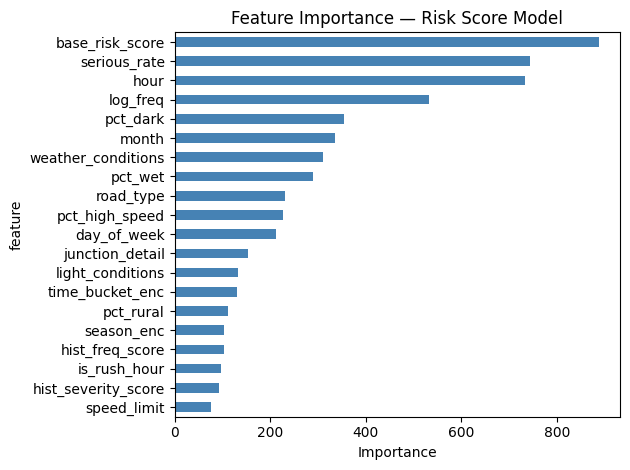

In [12]:
# 10. Feature importance
importance = pd.DataFrame({
    'feature'   : feature_cols,
    'importance': model.feature_importances_
}).sort_values('importance', ascending=False)

print(f"\n Top 15 Features ")
print(importance.head(15).to_string(index=False))

plt.figure(figsize=(10, 8))
importance.head(20).plot(kind='barh', x='feature', y='importance',
                          legend=False, color='steelblue')
plt.title('Feature Importance — Risk Score Model')
plt.xlabel('Importance')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig(OUTPUT_DIR2 + 'feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()


In [13]:
# 11. Save everything
joblib.dump(model,      OUTPUT_DIR1 + 'risk_model_v2.pkl')
joblib.dump(le_time,    OUTPUT_DIR1 + 'le_time.pkl')
joblib.dump(le_season,  OUTPUT_DIR1 + 'le_season.pkl')
joblib.dump(le_surface, OUTPUT_DIR1 + 'le_surface.pkl')
joblib.dump(scaler,     OUTPUT_DIR1 + 'scaler.pkl')
grid_history.to_csv(LOAD_DIR + 'grid_history.csv', index=False)